# Which method to fix the v1 segmentations? Part 1: measurements

Three ways of getting a better whole-hemisphere segmentation than `build_3d_segmentation.py` (v1)
are compared on the **5 NextBrain cases** (EX9-19, P41-16, P57-16, P58-16, P85-18), at 0.2 mm:

| name here | what it is |
|---|---|
| `v1` | `build_3d_segmentation.py`: nearest section. The starting point |
| `v1 + restore` | **option 1**: v1, then `dev/wp2/fill_holes/manual/restore.py` (default parameters) |
| `v2` | **option 2**: `build_3d_segmentation_v2.py` (default parameters) |
| `v2 + restore` | **option 3**: v2, then `restore.py` (default parameters). Added after the first results, because options 1 and 2 fix different artefacts |

There is **no ground truth** for these hemispheres. So the notebook does not give one score: it
measures separately what each method changes, what it fixes, and what it may damage. Only section 8
(held-out sections) compares with real data.

Contents:
1. Cost
2. How much each method changes v1
3. Volume of every label, and the labels that change the most
4. Gaps, cracks and holes: what is fixed, what is filled
5. Agreement with the MRI
6. Fidelity to the original histology sections
7. Smoothness (staircase)
8. Held-out sections (ground truth)
9. Summary: pros, cons and recommendation

Everything is read from the tables in `outputs/methods_comparison/tables/`. They are produced by:

```bash
./run_methods_comparison.sh      # v1, v1 + restore, v2 and v2 + restore for the 5 cases -> outputs/methods_comparison/<method>/
python compare_methods.py        # the tables (about 30 min); the notebook adds a few summary tables
python heldout_sections.py       # held-out section test
```

The images are in the second notebook, `methods_comparison_2_visual.ipynb`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_colwidth", 60, "display.width", 250)

HERE = os.path.abspath(".")
OUT = os.path.join(HERE, "outputs", "methods_comparison")
T = os.path.join(OUT, "tables")
METHODS = ["v1", "v1_restore", "v2", "v2_restore"]
NAME = {"v1": "v1", "v1_restore": "v1 + restore", "v2": "v2", "v2_restore": "v2 + restore"}
COL = {"v1": "0.55", "v1_restore": "tab:blue", "v2": "tab:orange", "v2_restore": "tab:green"}
FIX = ["v1_restore", "v2", "v2_restore"]        # the three candidates: options 1, 2 and 3

vol = pd.read_csv(os.path.join(T, "volumes.csv"))
glob = pd.read_csv(os.path.join(T, "global_metrics.csv"))
filled = pd.read_csv(os.path.join(T, "filled_regions.csv"))
added = pd.read_csv(os.path.join(T, "added_voxels.csv"))
sect = pd.read_csv(os.path.join(T, "section_fidelity.csv"))
sect_lab = pd.read_csv(os.path.join(T, "section_fidelity_labels.csv"))
runtime = pd.read_csv(os.path.join(T, "runtime.csv"))
CASES = sorted(vol.case.unique())
print("cases:", CASES)

def by_method(df, col, fmt="{:.1f}"):
    """Table case x method of one column, plus the mean over the cases."""
    t = df.pivot(index="case", columns="method", values=col)[METHODS]
    t.loc["mean"] = t.mean()
    return t.rename(columns=NAME).style.format(fmt)

def bars(ax, df, col, title, ylabel, methods=METHODS):
    t = df.pivot(index="case", columns="method", values=col)[methods]
    x = np.arange(len(t)); w = 0.8 / len(methods)
    for n, m in enumerate(methods):
        ax.bar(x + (n - (len(methods) - 1) / 2) * w, t[m], w, color=COL[m], label=NAME[m])
    ax.set_xticks(x); ax.set_xticklabels(t.index, fontsize=8); ax.set_title(title, fontsize=10); ax.set_ylabel(ylabel)

cases: ['EX9-19', 'P41-16', 'P57-16', 'P58-16', 'P85-18']


## 1. Cost: run time and memory

Wall time of one case at 0.2 mm (the five cases were run in parallel on the same machine, so the
times are a little longer than for a single run). For `v1 + restore` the total includes `v1`.

In [2]:
rt = runtime.pivot(index="case", columns="method", values="wall_total_s")[METHODS] / 60
rt.loc["mean"] = rt.mean()
mem = runtime.pivot(index="case", columns="method", values="peak_gb")[METHODS]
mem.loc["mean"] = mem.mean()
display(pd.concat({"wall time (min, total)": rt.rename(columns=NAME), "peak memory (GB)": mem.rename(columns=NAME)}, axis=1).style.format("{:.1f}"))

## 2. How much each method changes v1

Every voxel of the output of a method is compared with `v1`:
- **added**: labelled by the method, unlabelled in v1 (gaps, cracks and holes that were filled);
- **removed**: labelled in v1, unlabelled in the method;
- **relabelled**: labelled in both, with a different label.

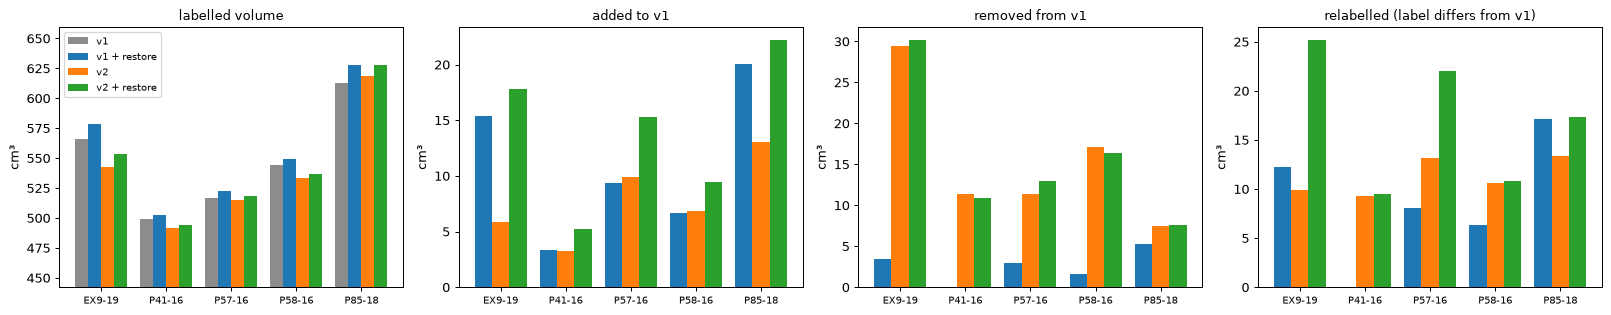

,n_labels,labels_lost_vs_v1,labelled_cm3,added_cm3,removed_cm3,relabelled_cm3,same_label_where_both_pct
method,,,,,,,
v1,332.00,0.00,547.86,0.00,0.00,0.00,100.00
v1 + restore,332.00,0.00,556.16,10.96,2.66,8.79,98.45
v2,331.80,0.20,540.26,7.77,15.37,11.29,97.88
v2 + restore,331.80,0.20,546.24,13.99,15.61,16.98,96.81


In [3]:
fig, axs = plt.subplots(1, 4, figsize=(18, 3.6))
bars(axs[0], glob, "labelled_cm3", "labelled volume", "cm³")
bars(axs[1], glob, "added_cm3", "added to v1", "cm³", FIX)
bars(axs[2], glob, "removed_cm3", "removed from v1", "cm³", FIX)
bars(axs[3], glob, "relabelled_cm3", "relabelled (label differs from v1)", "cm³", FIX)
axs[0].legend(fontsize=8); axs[0].set_ylim(glob.labelled_cm3.min() * 0.9, None)
plt.tight_layout(); plt.show()

cols = ["n_labels", "labels_lost_vs_v1", "labelled_cm3", "added_cm3", "removed_cm3", "relabelled_cm3", "same_label_where_both_pct"]
g = glob.groupby("method")[cols].mean().loc[METHODS].rename(index=NAME)
display(g.style.format("{:.2f}").set_caption("mean over the 5 cases"))

## 3. Volume of every label

`volumes.csv` has the volume of every label, case and method. Here each of the three candidates is compared with
`v1` through the ratio `volume(method) / volume(v1)`: 1 means unchanged, 2 means twice the volume.

1660 label-case pairs, 333 different labels


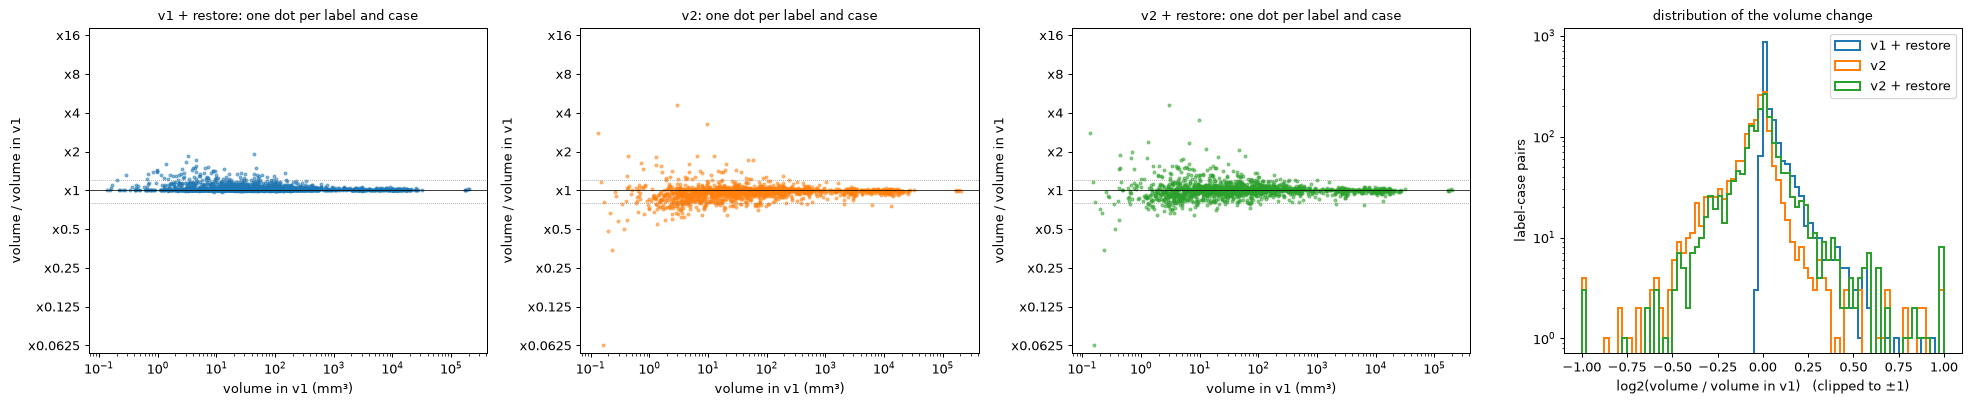

In [4]:
w = vol.pivot_table(index=["case", "label", "name", "l1"], columns="method", values="mm3", fill_value=0).reset_index()
for m in FIX:
    w["ratio_" + m] = np.where(w.v1 > 0, w[m] / w.v1.where(w.v1 > 0), np.nan)
w.to_csv(os.path.join(T, "volumes_wide.csv"), index=False)
print(f"{len(w)} label-case pairs, {w.label.nunique()} different labels")

fig, axs = plt.subplots(1, len(FIX) + 1, figsize=(22, 4.6))
for ax, m in zip(axs, FIX):
    r = np.log2(w["ratio_" + m].clip(1 / 16, 16))
    ax.scatter(w.v1, r, s=5, alpha=0.5, color=COL[m]); ax.set_xscale("log")
    ax.axhline(0, color="k", lw=0.6)
    for y in (np.log2(0.8), np.log2(1.2)): ax.axhline(y, color="gray", lw=0.6, ls=":")
    ax.set_yticks(np.arange(-4, 5)); ax.set_yticklabels([f"x{2.0**k:g}" for k in range(-4, 5)]); ax.set_ylim(-4.2, 4.2)
    ax.set_xlabel("volume in v1 (mm³)"); ax.set_ylabel("volume / volume in v1")
    ax.set_title(f"{NAME[m]}: one dot per label and case", fontsize=10)
bins = np.linspace(-1, 1, 81)
for m in FIX:
    axs[-1].hist(np.log2(w["ratio_" + m].dropna().clip(0.5, 2)), bins, histtype="step", lw=1.6, color=COL[m], label=NAME[m])
axs[-1].set_yscale("log"); axs[-1].set_xlabel("log2(volume / volume in v1)   (clipped to ±1)"); axs[-1].set_ylabel("label-case pairs")
axs[-1].set_title("distribution of the volume change", fontsize=10); axs[-1].legend()
plt.tight_layout(); plt.show()

### How many labels change, by size of the structure

In [5]:
size_bins = [0, 10, 100, 1000, np.inf]; size_names = ["< 10 mm³", "10-100 mm³", "100-1000 mm³", "> 1000 mm³"]
w["size"] = pd.cut(w.v1, size_bins, labels=size_names, right=False)
rows = []
for m in FIX:
    for s, d in list(w[w.v1 > 0].groupby("size", observed=True)) + [("all", w[w.v1 > 0])]:
        r = d["ratio_" + m]
        rows.append({"method": NAME[m], "size in v1": s, "label-case pairs": len(d),
                     "median change %": 100 * (r.median() - 1),
                     "within ±5 %": 100 * ((r - 1).abs() <= 0.05).mean(), "within ±10 %": 100 * ((r - 1).abs() <= 0.10).mean(),
                     "beyond ±20 %": 100 * ((r - 1).abs() > 0.20).mean(), "beyond ±50 %": 100 * ((r - 1).abs() > 0.50).mean(),
                     "label lost": int((d[m] == 0).sum())})
chg = pd.DataFrame(rows)
chg.to_csv(os.path.join(T, "volume_change_by_size.csv"), index=False)
display(chg.set_index(["method", "size in v1"]).style.format({c: "{:.1f}" for c in chg.columns[3:8]}))

### The structures that change the most

For every label the ratio is summarised over the cases where the label exists: median, minimum and
maximum. Labels are ranked by the median of `|log2 ratio|`, so that x2 and x0.5 count the same.
Two rankings are given for each method: relative change (dominated by tiny structures) and absolute
change in mm³ (dominated by large ones).

In [6]:
def ranking(m):
    d = w[w.v1 > 0].copy()
    d["abslog"] = np.log2(d["ratio_" + m].clip(lower=1e-3)).abs()
    d["diff"] = d[m] - d.v1
    g = d.groupby(["label", "name", "l1"]).agg(cases=("case", "size"), v1_mm3=("v1", "median"), ratio_median=("ratio_" + m, "median"),
                                                 ratio_min=("ratio_" + m, "min"), ratio_max=("ratio_" + m, "max"),
                                                 score=("abslog", "median"), diff_mm3=("diff", "median")).reset_index()
    return g

fmt = {"v1_mm3": "{:.1f}", "ratio_median": "x{:.2f}", "ratio_min": "x{:.2f}", "ratio_max": "x{:.2f}", "diff_mm3": "{:+.1f}"}
rank = {m: ranking(m) for m in FIX}
for m in FIX:
    r = rank[m]
    r.sort_values("score", ascending=False).to_csv(os.path.join(T, f"label_ranking_{m}.csv"), index=False)
    top = r[r.cases >= 3].sort_values("score", ascending=False).head(15).drop(columns=["score", "l1"])
    display(top.style.format(fmt).hide(axis="index").set_caption(f"{NAME[m]}: largest RELATIVE change (labels present in at least 3 cases)"))

label,name,cases,v1_mm3,ratio_median,ratio_min,ratio_max,diff_mm3
617,rostral_(anterior)_medullary_velum,5,6.6,x1.38,x1.20,x1.72,+3.3
842,decussation_of_trochlear_nerve_fibres,5,2.5,x1.35,x1.23,x1.45,+0.9
493,habenular_commissure,5,5.0,x1.29,x1.10,x1.49,+1.4
386,root_of_oculomotor_nerve,5,4.3,x1.27,x1.08,x1.42,+0.8
470,subcommissural_organ,5,1.8,x1.25,x1.15,x1.38,+0.4
610,central_gray_of_pons,5,87.0,x1.21,x1.08,x1.22,+18.0
150,median_preoptic_nucleus,5,5.7,x1.20,x1.10,x1.27,+1.2
436,interpeduncular_nucleus,5,1.7,x1.20,x1.06,x1.61,+0.2
765,central_gray_of_medulla_oblongata,4,11.4,x1.19,x1.14,x1.37,+2.6
227,periventricular_nucleus__tuberal_portion,5,9.0,x1.17,x1.08,x1.84,+0.9


label,name,cases,v1_mm3,ratio_median,ratio_min,ratio_max,diff_mm3
685,inferior_olive__dorsal_nucleus,5,2.4,x0.80,x0.72,x1.46,-0.4
842,decussation_of_trochlear_nerve_fibres,5,2.5,x0.73,x0.60,x0.81,-0.6
436,interpeduncular_nucleus,5,1.7,x0.74,x0.48,x0.95,-0.4
386,root_of_oculomotor_nerve,5,4.3,x0.74,x0.66,x0.94,-0.9
442,basal_ventral_medial_nucleus,5,4.6,x0.76,x0.71,x0.99,-0.6
520,trochlear_nucleus,5,1.4,x0.77,x0.58,x0.93,-0.3
586,commissure_of_inferior_colliculus,5,3.5,x0.78,x0.62,x0.86,-0.8
506,pineal_body,5,3.1,x0.78,x0.34,x1.19,-0.3
160,suprachiasmatic_nucleus,5,0.7,x0.92,x0.68,x1.62,-0.1
687,solitary_tract,5,3.0,x0.88,x0.75,x1.41,-0.5


label,name,cases,v1_mm3,ratio_median,ratio_min,ratio_max,diff_mm3
771,spinal_accessory_(supraspinal)_nucleus,3,4.3,x1.51,x1.02,x4.64,+2.2
447,edinger-westphal_nucleus_(accessory_oculomotor_nucleus),5,2.5,x1.00,x0.69,x2.38,+0.0
685,inferior_olive__dorsal_nucleus,5,2.4,x0.84,x0.72,x1.46,-0.4
160,suprachiasmatic_nucleus,5,0.7,x0.95,x0.74,x1.98,-0.0
442,basal_ventral_medial_nucleus,5,4.6,x0.77,x0.71,x0.99,-0.6
506,pineal_body,5,3.1,x0.78,x0.34,x1.27,-0.2
426,subparafascicular_nucleus_of_thalamus,5,6.1,x1.10,x0.00,x1.56,+0.9
687,solitary_tract,5,3.0,x0.95,x0.76,x1.44,-0.1
655,amiculum_of_the_olive,5,75.8,x1.02,x0.72,x1.26,+0.7
578,pulvinar_of_thalamus,5,44.2,x1.05,x0.81,x1.43,+2.7


In [7]:
for m in FIX:
    r = rank[m]
    top = r.reindex(r.diff_mm3.abs().sort_values(ascending=False).index).head(10).drop(columns=["score", "l1"])
    display(top.style.format(fmt).hide(axis="index").set_caption(f"{NAME[m]}: largest ABSOLUTE change (median over cases, mm³)"))

label,name,cases,v1_mm3,ratio_median,ratio_min,ratio_max,diff_mm3
7,white_matter_of_forebrain,5,181476.4,x1.01,x1.01,x1.03,+1823.9
2028,ctx-superiorfrontal,5,25568.0,x1.01,x1.00,x1.04,+305.8
2030,ctx-superiortemporal,5,12940.8,x1.02,x1.01,x1.03,+277.2
595,molecular_layer_of_pva,5,21075.4,x1.01,x1.01,x1.02,+247.8
50,anterior_horn_of_lateral_ventricle,5,6937.6,x1.04,x1.01,x1.04,+245.8
2024,ctx-precentral,5,17602.0,x1.01,x1.01,x1.02,+211.2
611,white_matter_of_hindbrain,5,12729.4,x1.01,x1.01,x1.02,+194.1
2029,ctx-superiorparietal,5,13998.8,x1.01,x1.00,x1.02,+169.0
2022,ctx-postcentral,5,12765.1,x1.01,x1.01,x1.02,+151.9
2009,ctx-inferiortemporal,5,11152.2,x1.01,x1.01,x1.03,+142.7


label,name,cases,v1_mm3,ratio_median,ratio_min,ratio_max,diff_mm3
7,white_matter_of_forebrain,5,181476.4,x0.99,x0.99,x1.01,-1228.0
595,molecular_layer_of_pva,5,21075.4,x0.97,x0.95,x1.01,-648.7
611,white_matter_of_hindbrain,5,12729.4,x0.97,x0.76,x0.98,-415.9
2011,ctx-lateraloccipital,5,12041.7,x0.97,x0.93,x1.02,-364.9
597,granular_cell_layer_of_pva,5,20182.5,x0.98,x0.92,x0.99,-362.2
2009,ctx-inferiortemporal,5,11152.2,x0.97,x0.92,x1.03,-347.2
2014,ctx-medialorbitofrontal,5,6205.4,x0.95,x0.77,x1.00,-330.2
2028,ctx-superiorfrontal,5,25568.0,x0.99,x0.94,x1.00,-295.5
2026,ctx-rostralanteriorcingulate,5,2110.7,x0.92,x0.78,x1.00,-274.6
2007,ctx-fusiform,5,10102.7,x0.97,x0.95,x1.03,-258.2


label,name,cases,v1_mm3,ratio_median,ratio_min,ratio_max,diff_mm3
7,white_matter_of_forebrain,5,181476.4,x1.01,x0.99,x1.03,+1183.8
50,anterior_horn_of_lateral_ventricle,5,6937.6,x1.06,x1.02,x1.07,+391.7
2011,ctx-lateraloccipital,5,12041.7,x0.97,x0.93,x1.02,-364.8
2009,ctx-inferiortemporal,5,11152.2,x0.97,x0.92,x1.04,-326.8
597,granular_cell_layer_of_pva,5,20182.5,x0.98,x0.93,x0.99,-324.0
595,molecular_layer_of_pva,5,21075.4,x0.99,x0.95,x1.02,-311.7
2014,ctx-medialorbitofrontal,5,6205.4,x0.95,x0.77,x1.03,-300.4
611,white_matter_of_hindbrain,5,12729.4,x0.98,x0.83,x1.00,-283.2
2007,ctx-fusiform,5,10102.7,x0.98,x0.96,x1.05,-252.9
2026,ctx-rostralanteriorcingulate,5,2110.7,x0.93,x0.78,x1.02,-232.8


The three rankings side by side: for the 25 labels that change the most in any method, the median
ratio of the three methods.

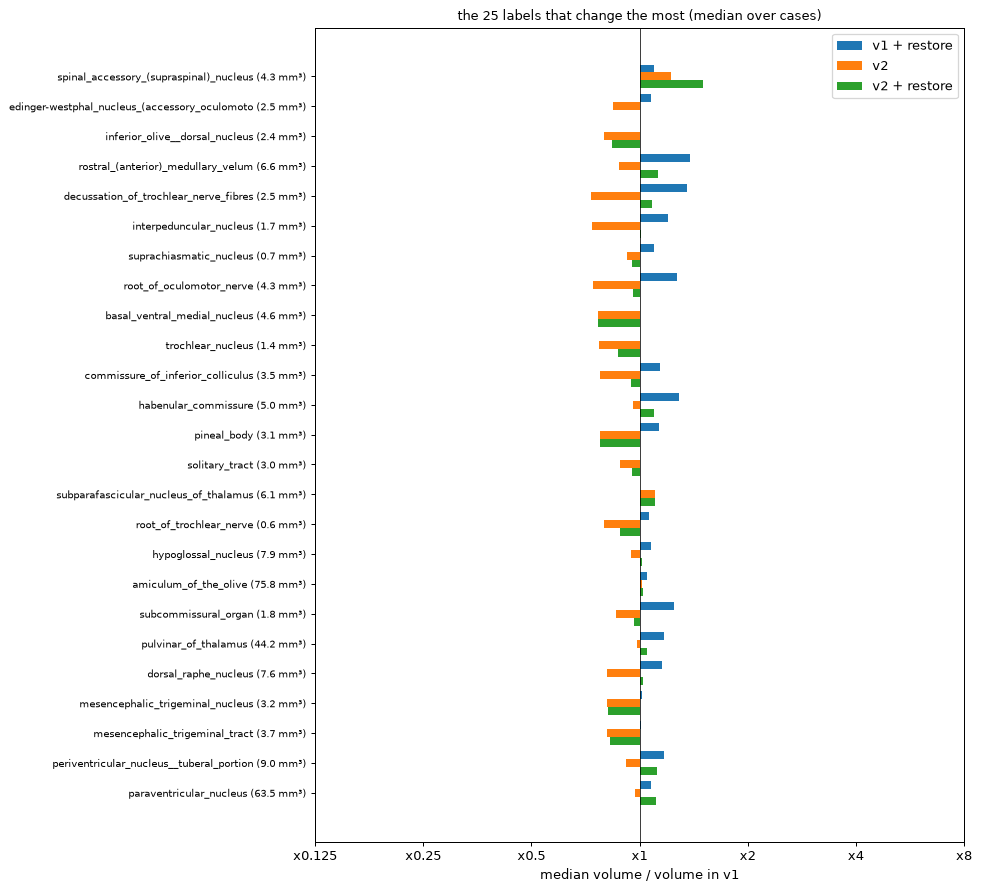

In [8]:
a = rank[FIX[0]].set_index("label")
both = pd.DataFrame({"name": a.name, "v1_mm3": a.v1_mm3, "cases": a.cases})
for m in FIX:
    both[m] = rank[m].set_index("label").ratio_median
both["s"] = np.max([rank[m].set_index("label").score.reindex(both.index) for m in FIX], axis=0)
both = both[both.cases >= 3].sort_values("s", ascending=False).head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 10))
y = np.arange(len(both)); bh = 0.8 / len(FIX)
for n, m in enumerate(FIX):
    ax.barh(y + ((len(FIX) - 1) / 2 - n) * bh, np.log2(both[m].clip(1 / 16, 16)), bh, color=COL[m], label=NAME[m])
ax.set_yticks(y); ax.set_yticklabels([f"{n[:45]} ({v:.1f} mm³)" for n, v in zip(both.name, both.v1_mm3)], fontsize=8)
ax.set_xticks(np.arange(-3, 4)); ax.set_xticklabels([f"x{2.0**k:g}" for k in range(-3, 4)]); ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("median volume / volume in v1"); ax.legend(); ax.set_title("the 25 labels that change the most (median over cases)", fontsize=10)
plt.tight_layout(); plt.show()

### Is the volume change the same in every case?

If a method changes a label by the same factor in the five hemispheres, the change is systematic
(a property of the method). If the factor is very different from case to case, it depends on the
accidents of each reconstruction (a missing section, a gap at that place).
The figure shows, for each label present in the five cases, the spread of the ratio over cases
(max / min).

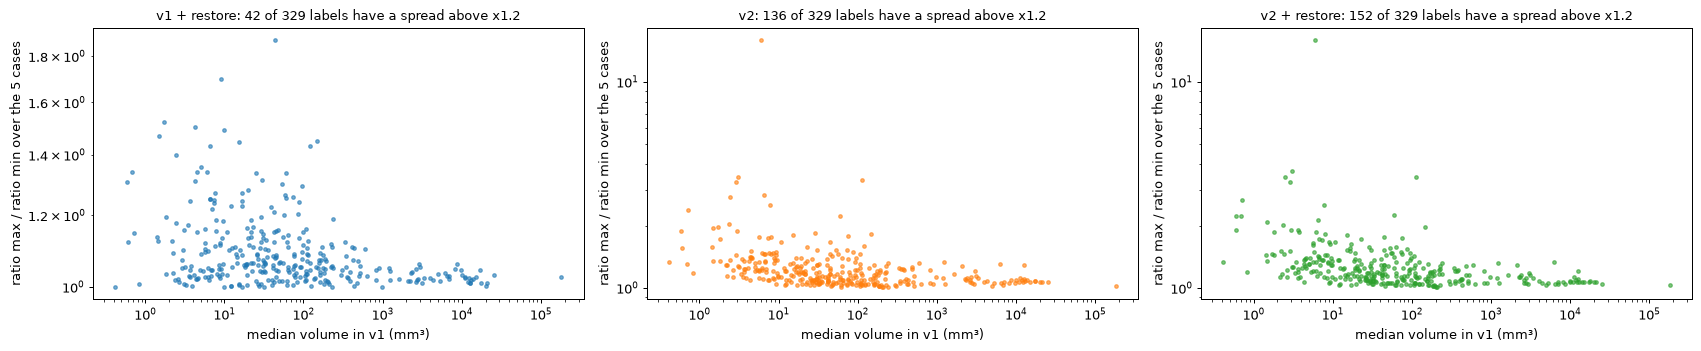

In [9]:
fig, axs = plt.subplots(1, len(FIX), figsize=(19, 4))
for ax, m in zip(axs, FIX):
    r = rank[m]; r = r[r.cases == len(CASES)]
    spread = r.ratio_max / r.ratio_min.clip(lower=1e-3)
    ax.scatter(r.v1_mm3, spread.clip(upper=16), s=8, color=COL[m], alpha=0.6); ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("median volume in v1 (mm³)"); ax.set_ylabel("ratio max / ratio min over the 5 cases")
    ax.set_title(f"{NAME[m]}: {int((spread > 1.2).sum())} of {len(r)} labels have a spread above x1.2", fontsize=10)
plt.tight_layout(); plt.show()

## 4. Gaps, cracks and holes

### What is left in each output

A **thin unlabelled run** is a run of at most 2.4 mm of unlabelled voxels along one axis, with
tissue at both ends. They are counted separately by the class of the two labels at the ends:
- both **non-cortical** (white matter, deep grey, brainstem...): an artefact (block gap or crack);
- both **cortical**: a sulcus, or an artefact that crosses the cortex. They cannot be told apart
  with this test, so a lower number is not necessarily better here.

The AP axis is the section axis of the cerebrum, where the block gaps are.

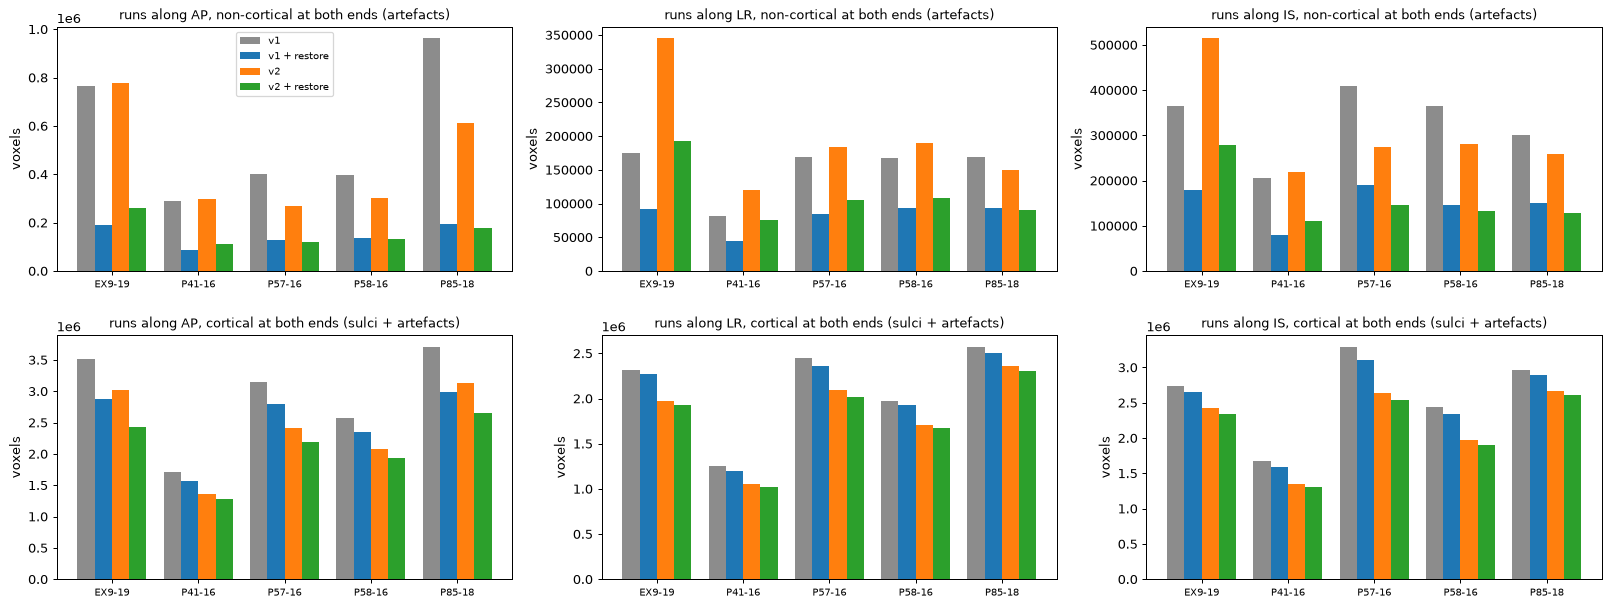

method,v1,v1 + restore,v2,v2 + restore
runs_AP_noncortex_vox,100%,26%,80%,28%
runs_LR_noncortex_vox,100%,53%,129%,75%
runs_IS_noncortex_vox,100%,45%,94%,48%
runs_AP_wm_vox,100%,16%,74%,15%
runs_LR_wm_vox,100%,37%,107%,42%
runs_IS_wm_vox,100%,29%,88%,29%
runs_AP_cortex_vox,100%,86%,82%,71%
runs_LR_cortex_vox,100%,97%,87%,85%
runs_IS_cortex_vox,100%,96%,84%,82%
runs_AP_mixed_vox,100%,59%,81%,54%


In [10]:
fig, axs = plt.subplots(2, 3, figsize=(18, 7))
for col, ax_name in enumerate(["AP", "LR", "IS"]):
    bars(axs[0, col], glob, f"runs_{ax_name}_noncortex_vox", f"runs along {ax_name}, non-cortical at both ends (artefacts)", "voxels")
    bars(axs[1, col], glob, f"runs_{ax_name}_cortex_vox", f"runs along {ax_name}, cortical at both ends (sulci + artefacts)", "voxels")
axs[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

cols = [f"runs_{a}_{k}_vox" for k in ("noncortex", "wm", "cortex", "mixed") for a in ("AP", "LR", "IS")] + ["enclosed_hole_vox"]
g = glob.groupby("method")[cols].mean().loc[METHODS]
g = (100 * g / g.loc["v1"]).rename(index=NAME).T
g.to_csv(os.path.join(T, "residual_runs_pct_of_v1.csv"))
display(g.style.format("{:.0f}%").set_caption("residual artefact voxels, as % of v1 (mean over the 5 cases)"))

### What each method does with the unlabelled regions of v1

The unlabelled voxels of `v1` are split into regions, and for each region the table gives the
percentage that the method labels:
- `gap_noncortex`: thin runs (any axis) between non-cortical labels → **should be filled**;
- `enclosed_hole`: cavities not connected to the outside → mostly should be filled (but most of the
  lateral ventricle is unlabelled in NextBrain and is a real cavity);
- `run_cortex`: thin runs between cortical labels → sulci and cortical gaps mixed: **filling a lot
  of it means closing sulci**;
- `run_mixed`: one end cortical, the other not;
- `other_inside_mri` / `other_outside_mri`: all the other unlabelled voxels, where the MRI has /
  does not have signal → should stay empty.

`plausible` is the percentage of the filled voxels whose MRI intensity is within 2 SD of the mean
intensity of the label they received (mean and SD measured on the v1 voxels of that label, same
case). For the voxels of v1 itself this percentage is about 93-95%.

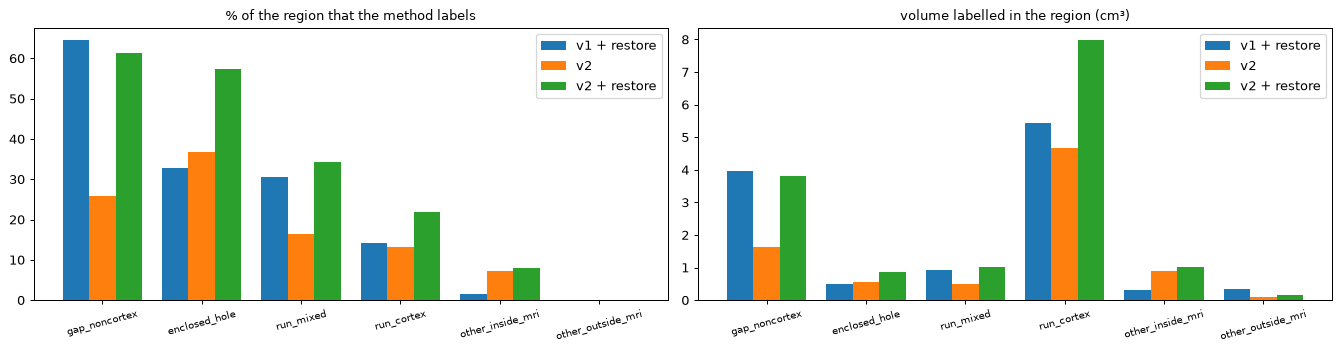

In [11]:
f = filled.groupby(["region", "method"])[["region_vox", "filled_vox", "filled_pct", "filled_plausible_pct", "filled_as_cortex_pct"]].mean().reset_index()
order = ["gap_noncortex", "enclosed_hole", "run_mixed", "run_cortex", "other_inside_mri", "other_outside_mri"]
t = f[f.method.isin(FIX)].pivot(index="region", columns="method", values=["filled_pct", "filled_plausible_pct"]).loc[order]
t.insert(0, "region size in v1 (cm³)", f[f.method == "v1"].set_index("region").region_vox.loc[order] * 0.008 / 1000)
display(t.style.format("{:.1f}").set_caption("mean over the 5 cases"))

fig, axs = plt.subplots(1, 2, figsize=(15, 4))
x = np.arange(len(order))
for n, m in enumerate(FIX):
    d = f[f.method == m].set_index("region").loc[order]
    bw = 0.8 / len(FIX); off = (n - (len(FIX) - 1) / 2) * bw
    axs[0].bar(x + off, d.filled_pct, bw, color=COL[m], label=NAME[m])
    axs[1].bar(x + off, d.filled_vox * 0.008 / 1000, bw, color=COL[m], label=NAME[m])
for ax, t_ in zip(axs, ("% of the region that the method labels", "volume labelled in the region (cm³)")):
    ax.set_xticks(x); ax.set_xticklabels(order, fontsize=8, rotation=15); ax.set_title(t_, fontsize=10); ax.legend()
plt.tight_layout(); plt.show()

### How far from real data are the added voxels

For every voxel that a method adds to v1, the distance to the nearest labelled voxel of v1. A thin
gap closed from both sides gives short distances; labels extended far from any section give long
ones. The longer the distance, the more the added label is an extrapolation.

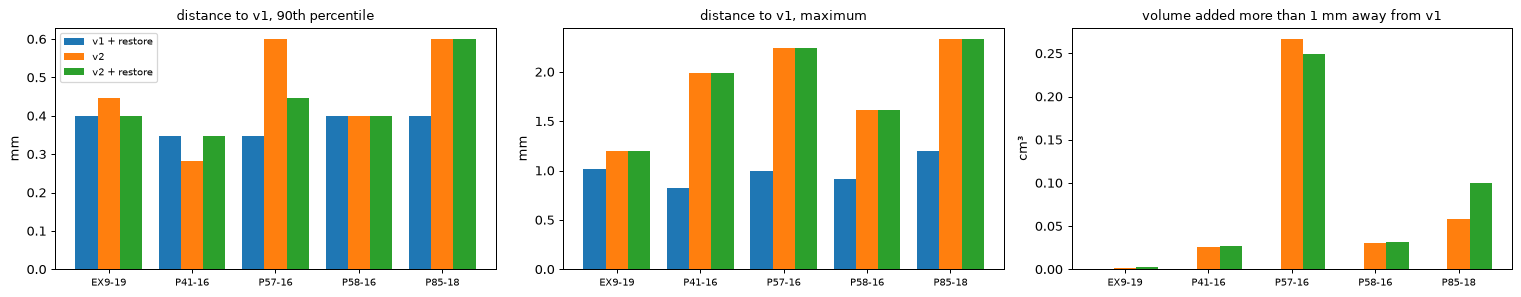

In [12]:
dist = pd.read_csv(os.path.join(T, "added_distance.csv"))
d = dist[dist.region == "all"]
fig, axs = plt.subplots(1, 3, figsize=(17, 3.4))
bars(axs[0], d, "p90_mm", "distance to v1, 90th percentile", "mm", FIX); axs[0].legend(fontsize=8)
bars(axs[1], d, "max_mm", "distance to v1, maximum", "mm", FIX)
bars(axs[2], d, "beyond_1mm_cm3", "volume added more than 1 mm away from v1", "cm³", FIX)
plt.tight_layout(); plt.show()
t = dist.groupby(["region", "method"])[["added_cm3", "median_mm", "p90_mm", "p99_mm", "max_mm", "beyond_1mm_cm3"]].mean().loc[["all", "cerebrum", "cerebellum", "brainstem"]]
display(t.rename(index=NAME, level=1).style.format("{:.2f}").set_caption("mean over the 5 cases (max_mm: mean of the per-case maxima)"))

## 5. Agreement with the MRI

The MRI is the only independent image of each hemisphere. Three checks:
- **variance explained**: fraction of the variance of the MRI intensity (over labelled voxels)
  explained by the labels. Higher = label borders follow the MRI borders better;
- **labels where the MRI is zero**: labelled voxels outside the masked MRI (label leaking outside
  the brain, or structures that are not in the MRI);
- **plausibility of the added voxels**: as above, for all the voxels a method adds to v1.

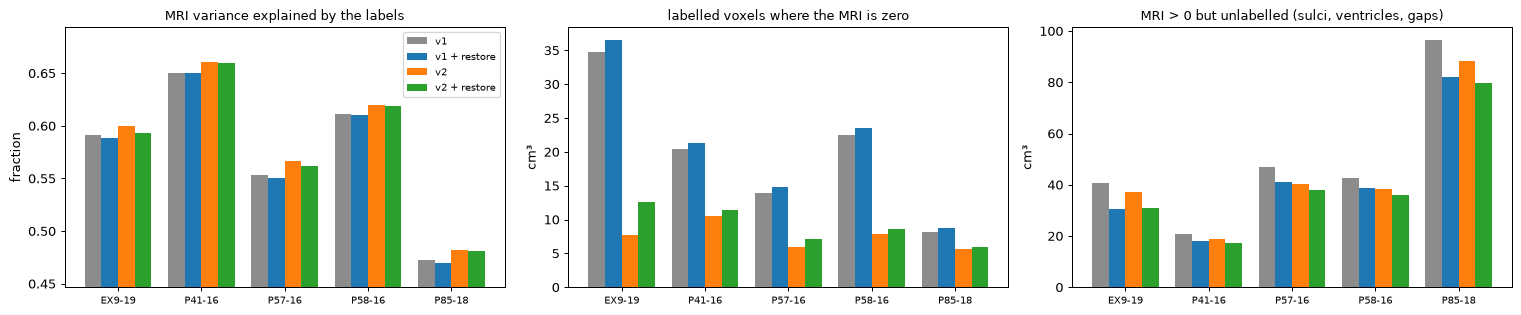

reference: plausible % of ALL the labelled voxels


method,v1,v1 + restore,v2,v2 + restore
case,,,,
EX9-19,94.7,94.6,94.9,94.7
P41-16,95.1,95.1,95.4,95.3
P57-16,94.7,94.6,95.0,94.9
P58-16,94.8,94.7,95.0,95.0
P85-18,95.2,95.2,95.4,95.4
mean,94.9,94.8,95.1,95.1


In [13]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.6))
bars(axs[0], glob, "mri_variance_explained", "MRI variance explained by the labels", "fraction")
axs[0].set_ylim(glob.mri_variance_explained.min() * 0.95, None); axs[0].legend(fontsize=8)
bars(axs[1], glob, "labels_where_mri_zero_cm3", "labelled voxels where the MRI is zero", "cm³")
bars(axs[2], glob, "mri_tissue_unlabelled_cm3", "MRI > 0 but unlabelled (sulci, ventricles, gaps)", "cm³")
plt.tight_layout(); plt.show()

a = added[added.method.isin(FIX)].copy(); a["cm3"] = a.vox * 0.008 / 1000
t = a.groupby(["change", "label_class", "method"])[["cm3", "mri_zero_pct", "plausible_pct"]].mean().unstack("method")
display(t.style.format("{:.2f}").set_caption("voxels added to / removed from v1, by class of the label (mean over the 5 cases)"))
print("reference: plausible % of ALL the labelled voxels")
display(by_method(glob, "plausible_all_labelled_pct"))

## 6. Fidelity to the original histology sections

The only real data are the labelled sections. Every labelled pixel of every section (sampled at
0.2 mm) is looked up in each output volume, at its position in MRI space:
- **same label**: the volume has the label of the section;
- **unlabelled**: the volume is empty there;
- **other label**: the volume has a different label.

`usable` sections are those that v2 uses (labelled area ≥ 30% of the median of the block);
`partial` sections are the nearly empty ones that v2 ignores.

`v1` is not at 100% because the output voxel (0.2 mm) is larger than the section pixel (0.1 mm) and
because blocks overlap. It is the reference: the difference with v1 is what a method changes **on
the sections themselves**.

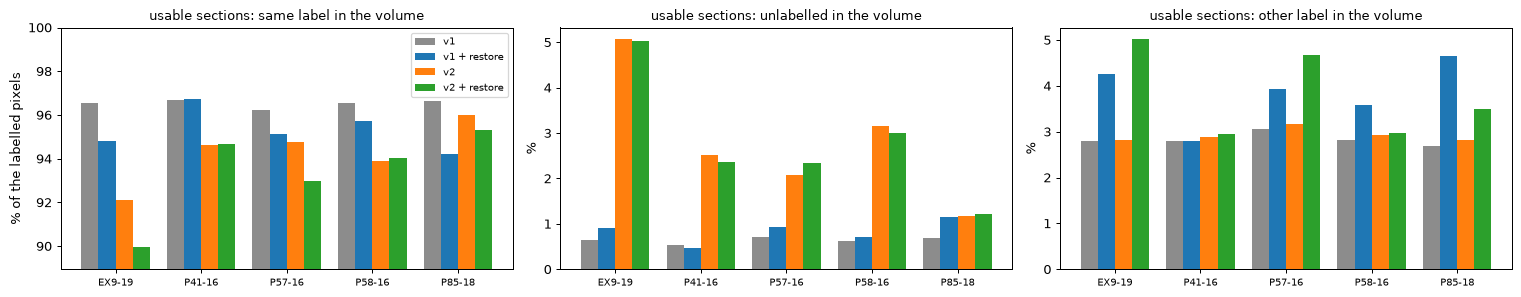

In [14]:
s = sect.groupby(["sections", "method"])[["pixels", "same_label_pct", "unlabelled_pct", "other_label_pct"]].mean().loc[["usable", "partial"]]
s = s.reindex(METHODS, level=1).rename(index=NAME, level=1)
display(s.style.format({"pixels": "{:,.0f}", "same_label_pct": "{:.2f}", "unlabelled_pct": "{:.2f}", "other_label_pct": "{:.2f}"}).set_caption("mean over the 5 cases"))

u = sect[sect.sections == "usable"]
fig, axs = plt.subplots(1, 3, figsize=(17, 3.4))
bars(axs[0], u, "same_label_pct", "usable sections: same label in the volume", "% of the labelled pixels"); axs[0].set_ylim(u.same_label_pct.min() - 1, 100); axs[0].legend(fontsize=8)
bars(axs[1], u, "unlabelled_pct", "usable sections: unlabelled in the volume", "%")
bars(axs[2], u, "other_label_pct", "usable sections: other label in the volume", "%")
plt.tight_layout(); plt.show()

Per label: the labels whose section pixels are worst preserved by each method, compared with v1
(labels with at least 200 section pixels in a case; mean over cases).

In [15]:
p = sect_lab[sect_lab.pixels >= 200].pivot_table(index=["label", "name"], columns="method", values="same_label_pct")
px = sect_lab[sect_lab.method == "v1"].groupby("label").pixels.mean()
for m in FIX:
    d = pd.DataFrame({"section pixels (mean)": px.reindex(p.index.get_level_values(0)).values, "v1": p.v1.values, NAME[m]: p[m].values,
                      "difference": (p[m] - p.v1).values}, index=p.index).dropna().sort_values("difference").head(12)
    display(d.style.format("{:.1f}").set_caption(f"{NAME[m]}: labels that lose most agreement with their own sections (% same label)"))
frac = {NAME[m]: [int(((p[m] - p.v1) < -t).sum()) for t in (1, 5, 10, 20)] for m in FIX}
display(pd.DataFrame(frac, index=[f"labels losing more than {t} points" for t in (1, 5, 10, 20)]))

,,section pixels (mean),v1,v1 + restore,difference
label,name,,,,
520,trochlear_nucleus,152.0,86.1,59.6,-26.5
683,superior_vestibular_nucleus,189.4,84.8,64.9,-19.9
600,mesencephalic_trigeminal_tract,263.2,71.5,55.1,-16.4
685,inferior_olive__dorsal_nucleus,223.6,75.4,59.2,-16.2
660,lateral_superior_olivary_nucleus,255.0,86.4,71.2,-15.2
409,stratum_radiatum_of_rostral_ca2,677.2,71.6,56.5,-15.1
411,stratum_oriens_of_rostral_ca2,788.8,71.2,56.2,-15.0
572,stratum_lucidum__of_caudal_ca3,386.8,78.0,63.5,-14.6
443,dorsal_division_of_central_lateral_nucleus,162.2,81.9,67.8,-14.1


,,section pixels (mean),v1,v2,difference
label,name,,,,
842,decussation_of_trochlear_nerve_fibres,190.0,77.6,58.4,-19.2
586,commissure_of_inferior_colliculus,256.0,84.3,71.1,-13.3
687,solitary_tract,254.4,85.6,74.2,-11.4
2026,ctx-rostralanteriorcingulate,99409.0,97.3,86.0,-11.2
505,ventral_medial_geniculate_nucleus,2653.8,92.5,81.4,-11.1
303,central_dorsal_nucleus_of_thalamus,540.4,81.5,70.6,-10.9
525,brachium_of_inferior_colliculus,1805.8,89.0,78.2,-10.8
386,root_of_oculomotor_nerve,407.6,63.8,53.3,-10.5
227,periventricular_nucleus__tuberal_portion,464.6,84.8,74.4,-10.3


,,section pixels (mean),v1,v2 + restore,difference
label,name,,,,
520,trochlear_nucleus,152.0,86.1,56.2,-30.0
683,superior_vestibular_nucleus,189.4,84.8,56.2,-28.6
685,inferior_olive__dorsal_nucleus,223.6,75.4,58.6,-16.8
842,decussation_of_trochlear_nerve_fibres,190.0,77.6,61.0,-16.7
303,central_dorsal_nucleus_of_thalamus,540.4,81.5,65.3,-16.2
505,ventral_medial_geniculate_nucleus,2653.8,92.5,77.8,-14.7
687,solitary_tract,254.4,85.6,70.9,-14.7
443,dorsal_division_of_central_lateral_nucleus,162.2,81.9,67.4,-14.5
756,gracile_nucleus,713.0,89.3,75.0,-14.3


,v1 + restore,v2,v2 + restore
labels losing more than 1 points,273,279,312
labels losing more than 5 points,98,83,135
labels losing more than 10 points,33,10,43
labels losing more than 20 points,1,0,2


## 7. Smoothness (staircase)

The staircase of v1 creates many small faces perpendicular to the section axis. The surface between
different labels (background included) is measured as the number of voxel faces along each axis.
A smaller surface for the same volumes means smoother borders. Filling gaps also removes surface,
so the faces along AP mix the two effects; LR and IS are little affected by the gaps.

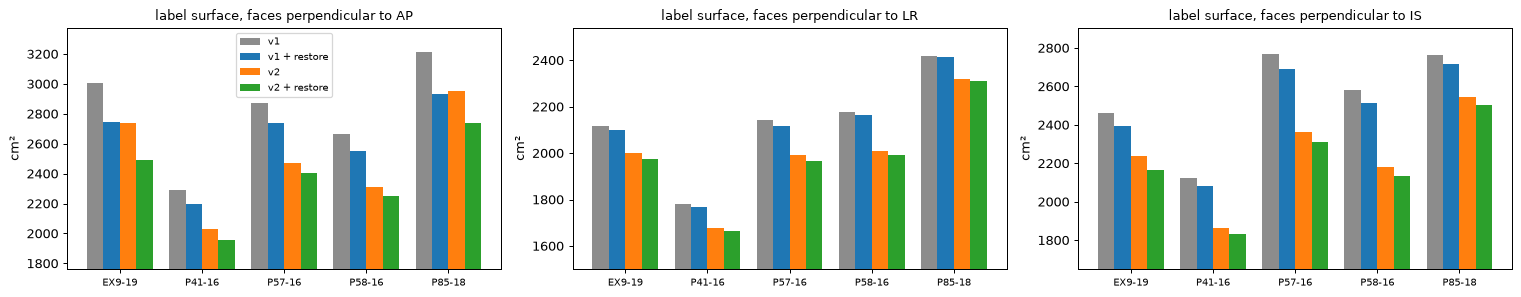

,faces_AP_cm2,faces_LR_cm2,faces_IS_cm2
method,,,
v1,100.0%,100.0%,100.0%
v1 + restore,93.8%,99.3%,97.6%
v2,89.0%,94.0%,88.1%
v2 + restore,84.3%,93.2%,86.2%


In [16]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.4))
for ax, a in zip(axs, ("AP", "LR", "IS")):
    bars(ax, glob, f"faces_{a}_cm2", f"label surface, faces perpendicular to {a}", "cm²"); ax.set_ylim(glob[f"faces_{a}_cm2"].min() * 0.9, None)
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
g = glob.groupby("method")[[f"faces_{a}_cm2" for a in ("AP", "LR", "IS")]].mean().loc[METHODS]
display((100 * g / g.loc["v1"]).rename(index=NAME).style.format("{:.1f}%").set_caption("label surface as % of v1 (mean over the 5 cases)"))

## 8. Held-out sections: the only test with a ground truth

`heldout_sections.py` hides one section and predicts it from its two neighbours, with the two rules
used to fill the space between sections:
- **nearest**: copy a neighbouring section (rule of `v1`; `restore.py` does not act between sections,
  so `v1 + restore` behaves the same here);
- **interp**: shape-based interpolation at `t = 0.5` (rule of `v2`, and therefore of `v2 + restore`).

The prediction is compared with the real hidden section. It is a hard version of the real problem:
the hidden section is exactly half-way, and the two neighbours are twice as far apart as in the real
reconstruction. For the densely sectioned blocks the held-out spacing (~0.7 mm) is the real spacing
of the other blocks.

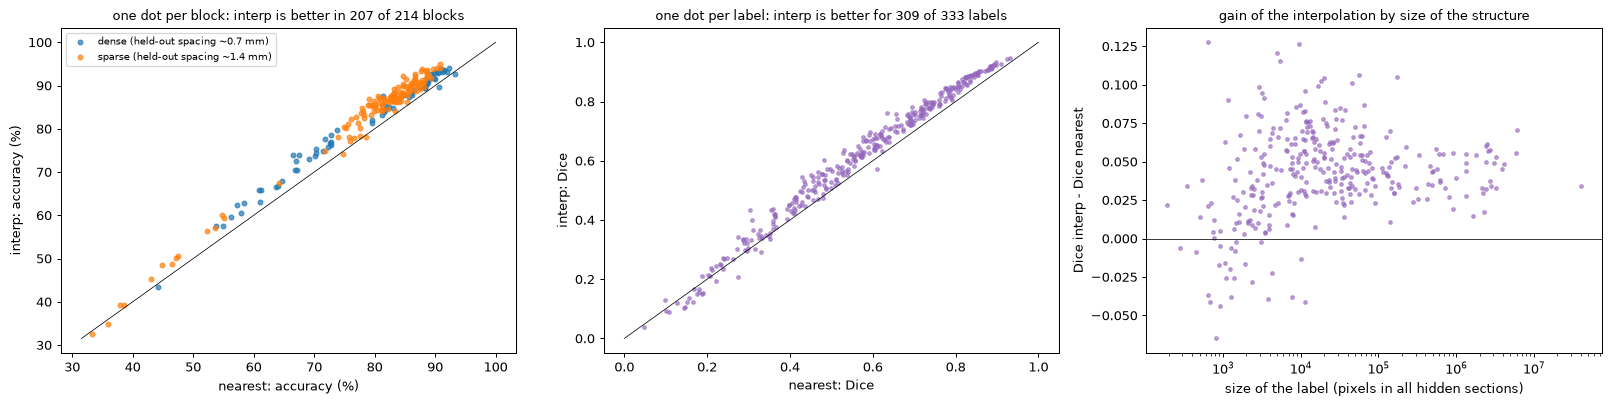

,labels,dice_nearest,dice_interp,interp_better,interp_worse
size,,,,,
"< 1,000 px",19,0.249,0.253,11,8
"1,000-10,000 px",112,0.418,0.455,98,14
"10,000-100,000 px",135,0.628,0.680,133,2
"> 100,000 px",67,0.795,0.839,67,0


label,name,px,nearest,interp,difference
598,dorsal_nucleus_of_lateral_lemniscus,806,0.274,0.209,-0.065
842,decussation_of_trochlear_nerve_fibres,911,0.166,0.122,-0.044
405,granular_layer_of_rostral_dentate_gyrus,"11,447",0.148,0.106,-0.041
436,interpeduncular_nucleus,671,0.143,0.102,-0.041
411,stratum_oriens_of_rostral_ca2,"3,759",0.330,0.291,-0.039
843,infundibular_stalk,"7,709",0.610,0.571,-0.038
586,commissure_of_inferior_colliculus,"1,280",0.187,0.149,-0.038
470,subcommissural_organ,635,0.190,0.153,-0.037
365,granular_layer_of_uncal_dentate_gyrus,"2,350",0.151,0.123,-0.028
569,stratum_oriens_of_caudal_ca2,"1,079",0.220,0.195,-0.026


label,name,px,nearest,interp,difference
433,parasubthalamic_nucleus,634,0.305,0.432,+0.128
157,layer_iii_of_piriform_cortex,"9,536",0.634,0.761,+0.126
196,supraoptic_nucleus,"4,915",0.483,0.603,+0.120
573,stratum_pyramidale_of_caudal_ca3,"5,379",0.428,0.544,+0.115
404,molecular_layer_of_rostral_dentate_gyrus,"56,617",0.530,0.636,+0.107
354,alveus,"172,684",0.576,0.681,+0.105
420,stratum_pyramidale_of_rostral_ca3,"20,046",0.594,0.699,+0.105
558,molecular_layer_of_caudal_dentate_gyrus,"18,262",0.451,0.553,+0.102
564,stratum_pyramidale_of_caudal_ca1,"45,989",0.655,0.756,+0.101
562,stratum_lacunosum-moleculare_of_caudal_ca1,"16,599",0.529,0.628,+0.099


In [17]:
hb = pd.read_csv(os.path.join(T, "heldout_blocks.csv")); hl = pd.read_csv(os.path.join(T, "heldout_labels.csv"))
hb["blocks"] = np.where(hb.dz_mm < 0.5, "dense (held-out spacing ~0.7 mm)", "sparse (held-out spacing ~1.4 mm)")
g = hb.groupby(["blocks", "case", "rule"])[["correct", "labelled"]].sum()
acc = (100 * g.correct / g.labelled).unstack("rule")[["nearest", "interp"]]
acc["difference"] = acc.interp - acc.nearest
display(acc.style.format("{:.2f}").set_caption("% of the labelled pixels of the hidden section that get the right label"))

p = hb.pivot_table(index=["case", "block", "blocks"], columns="rule", values="accuracy_pct").reset_index()
fig, axs = plt.subplots(1, 3, figsize=(18, 4.6))
for name, d in p.groupby("blocks"):
    axs[0].scatter(d.nearest, d.interp, s=14, alpha=0.7, label=name)
lim = [min(p.nearest.min(), p.interp.min()) - 1, 100]
axs[0].plot(lim, lim, "k", lw=0.6); axs[0].set_xlabel("nearest: accuracy (%)"); axs[0].set_ylabel("interp: accuracy (%)")
axs[0].set_title(f"one dot per block: interp is better in {int((p.interp > p.nearest).sum())} of {len(p)} blocks", fontsize=10); axs[0].legend(fontsize=8)

# Dice per label, pooled over the cases (weighted by size)
d = hl.pivot_table(index=["case", "blocks", "label", "name"], columns="rule", values="dice").reset_index()
d["true_px"] = hl[hl.rule == "interp"].set_index(["case", "blocks", "label", "name"]).true_px.reindex(pd.MultiIndex.from_frame(d[["case", "blocks", "label", "name"]])).values
lab = d.groupby(["label", "name"]).apply(lambda x: pd.Series({"px": x.true_px.sum(), "nearest": np.average(x.nearest, weights=x.true_px),
                                                               "interp": np.average(x.interp, weights=x.true_px)}), include_groups=False).reset_index()
lab["difference"] = lab.interp - lab.nearest
lab.to_csv(os.path.join(T, "heldout_labels_summary.csv"), index=False)
axs[1].scatter(lab.nearest, lab.interp, s=8, alpha=0.6, color="tab:purple"); axs[1].plot([0, 1], [0, 1], "k", lw=0.6)
axs[1].set_xlabel("nearest: Dice"); axs[1].set_ylabel("interp: Dice")
axs[1].set_title(f"one dot per label: interp is better for {int((lab.difference > 0).sum())} of {len(lab)} labels", fontsize=10)
axs[2].scatter(lab.px, lab.difference, s=8, alpha=0.6, color="tab:purple"); axs[2].set_xscale("log"); axs[2].axhline(0, color="k", lw=0.6)
axs[2].set_xlabel("size of the label (pixels in all hidden sections)"); axs[2].set_ylabel("Dice interp - Dice nearest")
axs[2].set_title("gain of the interpolation by size of the structure", fontsize=10)
plt.tight_layout(); plt.show()

bins = [0, 1e3, 1e4, 1e5, np.inf]; bn = ["< 1,000 px", "1,000-10,000 px", "10,000-100,000 px", "> 100,000 px"]
lab["size"] = pd.cut(lab.px, bins, labels=bn)
t = lab.groupby("size", observed=True).agg(labels=("label", "size"), dice_nearest=("nearest", "mean"), dice_interp=("interp", "mean"),
                                           interp_better=("difference", lambda x: int((x > 0).sum())), interp_worse=("difference", lambda x: int((x < 0).sum())))
display(t.style.format({"dice_nearest": "{:.3f}", "dice_interp": "{:.3f}"}).set_caption("mean Dice with the hidden section, by size of the label"))
fmt2 = {"px": "{:,.0f}", "nearest": "{:.3f}", "interp": "{:.3f}", "difference": "{:+.3f}"}
display(lab.sort_values("difference").head(10).drop(columns="size").style.format(fmt2).hide(axis="index").set_caption("labels where the interpolation is worst compared with nearest"))
display(lab.sort_values("difference").tail(10).iloc[::-1].drop(columns="size").style.format(fmt2).hide(axis="index").set_caption("labels where the interpolation helps most"))

## 9. Summary

One table with the main numbers (mean over the 5 cases). The arrow says which direction is better;
`=` marks a measure that is a cost or a choice rather than a quality.

In [18]:
gm = glob.groupby("method").mean(numeric_only=True).loc[METHODS]
pct = lambda c: 100 * gm[c] / gm.loc["v1", c]
hacc = hb.groupby("rule")[["correct", "labelled"]].sum(); hacc = 100 * hacc.correct / hacc.labelled
us = sect[sect.sections == "usable"].groupby("method").mean(numeric_only=True).loc[METHODS]
big = pd.Series({m: 100 * ((w.loc[w.v1 > 0, "ratio_" + m] - 1).abs() > 0.2).mean() if m != "v1" else 0.0 for m in METHODS})
dmax = dist[dist.region == "all"].groupby("method").max_mm.max().reindex(METHODS)
rtm = runtime.groupby("method").wall_total_s.mean().loc[METHODS] / 60
score = pd.DataFrame({
    "↓ white-matter gap voxels left along AP (% of v1)": pct("runs_AP_wm_vox"),
    "↓ non-cortical thin runs left, AP (% of v1)": pct("runs_AP_noncortex_vox"),
    "↓ non-cortical thin runs left, LR (% of v1)": pct("runs_LR_noncortex_vox"),
    "↓ label surface, AP faces (% of v1): staircase + gaps": pct("faces_AP_cm2"),
    "↓ label surface, IS faces (% of v1): staircase": pct("faces_IS_cm2"),
    "↑ held-out section: pixels with the right label (%)": pd.Series({m: hacc["interp"] if m.startswith("v2") else hacc["nearest"] for m in METHODS}),
    "↑ section pixels with the same label in the volume (%)": us.same_label_pct,
    "↓ section pixels left unlabelled in the volume (%)": us.unlabelled_pct,
    "↑ MRI variance explained by the labels": gm.mri_variance_explained,
    "↓ labelled voxels where the MRI is zero (cm³)": gm.labels_where_mri_zero_cm3,
    "= removed from v1 (cm³)": gm.removed_cm3,
    "= added to v1 (cm³)": gm.added_cm3,
    "= relabelled with respect to v1 (cm³)": gm.relabelled_cm3,
    "↓ label-case pairs whose volume changes more than 20% (%)": big,
    "↓ labels lost (mean per case)": gm.labels_lost_vs_v1,
    "↓ largest distance from an added voxel to a v1 label (mm)": dmax,
    "= run time, total (min)": rtm,
}).T[METHODS].rename(columns=NAME)
score.to_csv(os.path.join(T, "summary_scorecard.csv"))
display(score.style.format("{:.2f}"))

,v1,v1 + restore,v2,v2 + restore
↓ white-matter gap voxels left along AP (% of v1),100.00,15.99,73.69,15.36
"↓ non-cortical thin runs left, AP (% of v1)",100.00,26.18,79.94,28.41
"↓ non-cortical thin runs left, LR (% of v1)",100.00,53.48,129.42,75.20
"↓ label surface, AP faces (% of v1): staircase + gaps",100.00,93.81,89.03,84.27
"↓ label surface, IS faces (% of v1): staircase",100.00,97.62,88.06,86.20
↑ held-out section: pixels with the right label (%),82.18,82.18,85.53,85.53
↑ section pixels with the same label in the volume (%),96.53,95.31,94.28,93.39
↓ section pixels left unlabelled in the volume (%),0.64,0.84,2.80,2.79
↑ MRI variance explained by the labels,0.58,0.57,0.59,0.58
↓ labelled voxels where the MRI is zero (cm³),19.96,20.95,7.54,9.13


### What each option does well and badly

**Option 1: `v1 + restore`**

| | |
|---|---|
| ✔ | **Closes the block gaps.** 16% of the white-matter gap voxels of v1 are left (v2 leaves 74%); 64% of the non-cortical thin runs are filled (v2: 26%). This is consistent in the five cases. |
| ✔ | **Stays close to the data.** Nothing is added more than 1.2 mm away from a label of v1; 86% of the label-case pairs change volume by less than 10%; no label is lost. |
| ✔ | Removes little (2.7 cm³ per case) and is about twice as fast as v2 (4.4 min against 8.3 min). |
| ✘ | **Does not touch the staircase.** Between sections it is still nearest-section: on the held-out sections that rule is 3-4 points less accurate than the interpolation of v2. |
| ✘ | **Only finds gaps along the AP axis.** The gaps of the cerebellum (sagittal blocks) and of the brainstem (axial blocks) are not filled; see the visual notebook, section 3.2. |
| ✘ | The block-shift step moves blocks by one voxel: 8.8 cm³ of voxels change label and the agreement with the original sections drops from 96.5% to 95.3%. In P41-16, where no block was shifted, it stays at 96.7%. |
| ✘ | Filling with the nearest label makes thin midline and brainstem structures **grow** (rostral medullary velum x1.4, habenular commissure x1.3, in the five cases), and slightly increases the labels outside the MRI (20.0 → 20.9 cm³). |

**Option 2: `v2`**

| | |
|---|---|
| ✔ | **Removes the staircase.** Label surface -11% (AP) and -12% (IS), against -6% and -2% for restore. On the held-out sections the interpolation is better than nearest-section in 207 of 214 blocks (+2.8 points with neighbours 0.7 mm apart, +3.9 points at 1.4 mm) and for 309 of 333 labels. |
| ✔ | **Bridges the missing sections in every block orientation**, cerebellum and brainstem included. |
| ✔ | Follows the MRI a little better (variance explained 0.586 against 0.576) and removes the labels that lie outside the MRI mask (20.0 → 7.5 cm³). |
| ✘ | **Leaves most of the gaps.** 74% of the white-matter gap voxels are still there (EX9-19: 96%). Thin non-cortical runs along LR even increase (129% of v1). |
| ✘ | **Removes a lot**: 15.4 cm³ per case (7 to 29 cm³), most of it because the MRI mask is zero there (on average 73% of the cortical and 84% of the non-cortical voxels removed). 2.8% of the labelled pixels of the usable sections end up unlabelled (v1: 0.6%). Whether this is right depends on how much the MRI mask is trusted; `--no-trim` switches it off. |
| ✘ | **Small structures change more**: 23% of the labels under 10 mm³ change volume by more than 20% (restore: 11%), most of them shrink (several brainstem nuclei x0.73-0.80 in the five cases), and one label disappears in one case (subparafascicular nucleus of thalamus, P85-18, 20 voxels in v1). For labels under 1,000 pixels the held-out test shows no gain of the interpolation (Dice 0.25 for both rules). |
| ✘ | Extends labels further from the data than restore (up to 2.3 mm, by copying the last usable section of a block) and is the slowest of the two. |

**Option 3: `v2 + restore`**

| | |
|---|---|
| ✔ | **Closes the gaps as well as option 1**: 15% of the white-matter gap voxels of v1 are left (option 1: 16%), 28% of the non-cortical thin runs along AP (option 1: 26%). `restore.py` works on the output of v2 as well as on v1. |
| ✔ | **Smoothest result**: smallest label surface of the four (84% of v1 along AP, 86% along IS), and the between-section accuracy of v2 on the held-out sections (85.5% against 82.2%). |
| ✔ | Keeps what v2 adds in the cerebellum and brainstem (bridged sections), which option 1 cannot fill, and fills the largest share of the enclosed holes of v1 (57%, against 33% and 37%). |
| ✔ | Removes the thin runs along LR that v2 creates (129% → 75% of v1), although option 1 is still better there (53%). |
| ✘ | **Changes v1 the most**: 15.6 cm³ removed (the trimming of v2), 14.0 cm³ added, 17.0 cm³ relabelled. Agreement with the original sections is the lowest of the four: 93.4% (v1 96.5%). The loss is the sum of the two steps: section pixels left unlabelled by the trimming of v2 (2.8%) and labels moved by the block shifts of restore. |
| ✘ | **Small structures are the least stable**: 22% of the labels under 10 mm³ change by more than 20% and 5% by more than 50% (option 1: 11% and 1.7%). It inherits the label lost by v2 in P85-18. |
| ✘ | Fills more of the thin runs between cortical labels than the others (22%, against 14% and 13%). These runs are sulci and cortical gaps mixed, so this is the option where **sulcus closure most needs a visual check**. |
| ✘ | Slowest: 11 min per case (v2 8.4 min + restore 2.6 min). |
| ✘ | The block shifts found by `restore.py` on v2 are **different** from those found on v1 (none in P58-16 instead of 3 blocks, one block of P57-16 moved by 4 voxels instead of 1). The shift estimate is not stable; `--no-shifts` switches it off. |

### Recommendation

Options 1 and 2 are **not two solutions to the same problem**: `restore.py` fixes the gaps and
leaves the staircase, `v2` fixes the staircase and the missing sections and leaves most of the gaps.

1. **Best overall: option 3, `v2 + restore`.** It is the only one that removes both artefacts: the
   gap closure of option 1 and the smooth borders and bridged sections of option 2. Its costs are
   the costs of v2 (trimming, unstable small nuclei) plus the block shifts of restore.
2. **If the result must stay as close as possible to the histology: option 1, `v1 + restore`.**
   It closes the gaps just as well, changes the labels the least and loses no label, but keeps the
   staircase and does not fill the cerebellar and brainstem gaps.
3. **Option 2 alone is not enough**: 74% of the white-matter gap voxels remain.

Two things should be checked before adopting option 3 (or v2 in any form):
1. **The MRI trimming.** It removes 7-29 cm³ of labels per case. Look at the trimmed voxels of
   EX9-19 in the visual notebook; if the MRI mask is not reliable there, run v2 with `--no-trim`
   and then `restore.py`.
2. **Small nuclei.** If the volume of structures under ~10 mm³ matters, no option can be trusted
   for them: their volume depends on the method by 20% or more.

### Limits of this comparison

- No ground truth for the full volumes: all the numbers except the held-out test measure
  consistency (with v1, with the sections, with the MRI), not correctness.
- Thin runs between cortical labels are sulci and artefacts mixed. Options 1 and 2 fill a similar
  share of them (13-14%), option 3 more (22%). The filled voxels have plausible MRI intensities
  (94%, against 95% for all labelled voxels), but **sulcus closure could not be measured directly**.
- "Enclosed holes" can increase after closing gaps, because an unlabelled space that was open to
  the outside through a gap becomes enclosed. P85-18 shows this for the three options; it is not a
  failure of the hole filling.
- The held-out test doubles the section spacing and tests only the half-way position.
- Default parameters everywhere; the methods were not tuned.